# RL agent sims (261020): model characterisation by centrality strategy

Social (2-agent) self-play models trained in `Octagon/results/2610/261020` (0001-0012) and the top
level of `Octagon/results` (0013 onward, not yet moved). The batch asks whether giving both seats
the opponent input during training leads the policy to use it (`agent_training/READMEs/opponent_sensing.md`,
`Octagon/results/2610/261020/notes.txt`). Gamma is back at 0.99 to get a mix of central and
peripheral models.

| setting | 260723 | 260929 | 261020 |
| --- | --- | --- | --- |
| build | 260723 | 260914_01_social | 261014/build_261014_social_01 |
| extrinsic gamma | 0.99 | 0.998 | 0.99 |
| lambd | 0.95 | 0.95 | 0.95 |
| time_horizon | 128 | 128 | 128 |
| learning_rate / epsilon schedule | linear | constant | constant |
| max_steps | 4e6 | 7e6 | 4e6 |

In the 261014 build both seats sense each other, walls hide the opponent, and the opponent value is
proximity (1 - d/60) rather than distance. The observation size is unchanged. The step-penalty
clause still has `&& false`, so `step_penalty` (1e-3) is a per-step time cost charged on rests too,
as in 260723, 260914 and 260929.

Every model in this batch was trained on the standard recorded seed list, `DEFAULT_TRAINING_SEEDS`
in `agent_training/trainer_and_simulator_functions.py`. Model `NNNN` takes entry `NNNN` of that list,
so it trains on the same seed as `260929_NNNN` and `260914_NNNN`. This was checked against the seed
in each run's `configuration.yaml` (all of 0001-0041 match).

**Simulation.** Every model is run through the 261014 social build with `SocialConfig261020.yaml`,
the trial sequence `trials_100000_seed17.json`, seed 17, 201 episodes and sampled actions, as in the
earlier batches. Model 0041 stopped training at 1.7e6 steps and is not simulated.

**The characterisation axis is centrality at slice onset.** For each trial, at the frame the
walls appear, centrality `= 1 - r/R` (1 = arena centre, 0 = alcove back). A model's mean over
trials is roughly where it stands when the trial starts.

**Plan**
1. **The strategy axis.** Per-model slice-onset centrality, and whether it splits into groups.
2. **Fingerprint by strategy.** Which metrics separate the groups, and which vary within them.
3. **Multivariate fingerprint.** Whether centrality is still the main axis once every metric is in.
4. **Seeds and the earlier batches.** Whether a seed keeps its strategy from 260929 and 260914, how
   often seeds end up peripheral in each batch, and how the groups compare across batches.

Stages 1-3 are the standard analysis. The opponent-input checks listed in `notes.txt` are not in
this notebook.

**Choices** (matching the earlier sim notebooks): FoV = 110.0; both agents pooled (self-play);
every number comes from `analysis/model_characterisation.py`. Metric definitions are in
`demos/strategy_characterisation/fingerprint_metrics.md`.

### Results:
Models 0001-0040: 40 models, all simulated (0041 stopped training at 1.7e6 steps). 37 models
contribute 196-198 trials. 0016 and 0022 contribute 193 and 191, and 0003 contributes 103 (see below).

- Gamma 0.99 brings the peripheral group back. 18 of 40 models are peripheral (onset centrality
  0.004-0.265) and 22 central (0.599-0.922). The fixed cut and the GMM agree on every model. The gap
  between the groups is 0.335, narrower than 260929's 0.667
- The peripheral share (0.450, interval 0.293-0.615) matches 260723 (0.473, p = 0.84) and is above
  260929 (0.175, p = 0.015) and 260914 (0.067, p = 0.0004)
- Central models choose High less than in 260929 (`p_high` 0.862 against 0.999), close to 260723
  (0.851). Peripheral models choose it on 0.666
- Peripheral models stand still far more in the ITI (resting 0.287 against 0.024), travel less
  (18.2 against 40.5 units per ITI) and end 14.6% of trials without seeing a wall, against 1.0%
- Their resting is like 260929's peripheral models (0.335), not 260723's (0.102). The gamma change
  did not bring it back to the 260723 level
- Peripheral models score less per second (0.366 against 0.461), but reach the wall almost as fast
  (2.19 s against 1.94 s, eta² 0.16)
- PC1 of the fingerprint (centrality excluded) explains 51% and correlates -0.87 with centrality.
  Strategy is still the main axis
- Seeds barely keep their strategy. Of 39 seeds paired with 260929, 5 of its 7 peripheral seeds are
  peripheral here, and 13 of its 32 central seeds turned peripheral. Rank correlation +0.28 (p = 0.08)
- Some trials stall. 0003 has two trials of 482 s and 1454 s in which both agents stand still a
  metre apart, so it logs 105 trials and its score rate is 0.110. 0016 and 0022 each have two trials
  of 64-118 s. 260723 (also gamma 0.99) has 5 such trials across 4 models, and 260929 none, so
  this is not clearly new to the 261014 build

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import data_strings
import analysis.model_characterisation as mc
import data_extraction.data_saving as data_saving
import parse_data.identify_sim_filepaths as identify_sim_filepaths
import plotting.plot_octagon as plot_octagon

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)

# social self-play inference logs for this run live in a dated subfolder
BATCH = '261020'
SIM_DATA_FOLDER = os.path.join(data_strings.SIM_DATA_FOLDER, '2610', BATCH)

CURRENT_FOV = 110.0                 # agent camera FoV (total degrees)
RECOMPUTE = False                   # rebuild the cached long tables (loads every model's JSON)
LAST_MODEL = 40                     # 0041 stopped training at 1.7e6 steps

## Models included

A simulation writes `DONE.txt` when it finishes. Only folders holding it are loaded, so a run still
being simulated is never read half-written. `LAST_MODEL` caps the list at the fully trained models.
Trained models with no simulation folder are listed too. Runs 0013 onward are still at the top
level of `results/`, so both places are searched.

In [2]:
# find the simulated models, and keep those whose simulation finished
folders = dict(identify_sim_filepaths.get_model_folders(sim_data_folder=SIM_DATA_FOLDER))
done = {m: os.path.exists(os.path.join(SIM_DATA_FOLDER, f, 'DONE.txt')) for m, f in folders.items()}
ALL_MODELS = sorted(m for m, d in done.items() if d and m <= LAST_MODEL)

# find the trained models that have not been simulated yet, in the batch folder and the top level
RESULTS_ROOT = os.path.join(os.path.dirname(data_strings.SIM_DATA_FOLDER), 'results')
trained = sorted({m for m, f in identify_sim_filepaths.get_model_folders(sim_data_folder=RESULTS_ROOT)
                  if f.startswith(BATCH)} |
                 {m for m, _ in identify_sim_filepaths.get_model_folders(
                     sim_data_folder=os.path.join(RESULTS_ROOT, '2610', BATCH))})

print(f"models simulated and finished: {len(ALL_MODELS)}")
print(ALL_MODELS)
print(f"simulation still running (no DONE.txt): {sorted(m for m, d in done.items() if not d)}")
print(f"finished but above LAST_MODEL: {sorted(m for m, d in done.items() if d and m > LAST_MODEL)}")
print(f"trained but not simulated: {sorted(set(trained) - set(folders))}")

models simulated and finished: 40
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
simulation still running (no DONE.txt): []
finished but above LAST_MODEL: []
trained but not simulated: [41]


## Main pass over all models

One pass per model builds the long tables: `slice` (slice-onset centrality and x,z, one row per
trial x agent), `iti`, `vis`, `score`, `win` and `rt`. Each model is loaded, measured, then
discarded, so the batch stays memory-safe. The tables are cached, keyed on the model list, so a
new model being added triggers a rebuild.

In [3]:
# build the long tables, or load them if this model list is already cached
tables = data_saving.cached(f'model_characterisation_{BATCH}',
                            lambda: mc.collect_model_data(SIM_DATA_FOLDER, models=ALL_MODELS,
                                                          fov=CURRENT_FOV, verbose=False),
                            recompute=RECOMPUTE, stamp=tuple(ALL_MODELS))
USABLE_MODELS = mc.summarise_collection(tables, ALL_MODELS)
slice_df, iti_df = tables['slice'], tables['iti']

model_characterisation_261020: cached under (1, 2, 3, 4), now (1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40). Recomputing


model_characterisation_261020: computed and cached


usable models: 40 / 40
slice-onset rows: 15588 | ITIs: 15588 | visibility rows: 15588 | scored trials: 7794
trials per model: min 103, max 198


### Trial counts per model

Every model should contribute the same number of trials. One that contributes far fewer had its
simulation cut short, and its per-model means rest on less data.

In [4]:
# count the trials each model contributed, pooled over both agents
n_trials = (slice_df.groupby('model').size() // len(mc.PLAYERS)).rename('n_trials')
short = n_trials[n_trials < 0.9 * n_trials.median()]
print(f"trials per model: median {int(n_trials.median())}, min {int(n_trials.min())}, "
      f"max {int(n_trials.max())}")
print(f"models with a short run: {short.index.tolist() if len(short) else 'none'}")

trials per model: median 198, min 103, max 198
models with a short run: [3]


## Stage 1 - the strategy axis (centrality at slice onset)

**How to read the figures.** The first figure has one bar per model, ranked from lowest to highest
mean slice-onset centrality. Bar height is the model's mean over trials and both agents. The
whisker is the SD over those trials. The dotted line marks centrality 0.5, the fixed cut used
below. A centrality of 1 is the arena centre and 0 is the back of an alcove.

The second figure shows the same models in the same order, with each violin giving the spread of
single-trial centrality values. The red dot is the model mean.

**Why they are plotted.** The bars show whether the models spread smoothly along the axis or fall
into groups. The violins show whether a model starts every trial from about the same place, or
mixes positions from trial to trial.

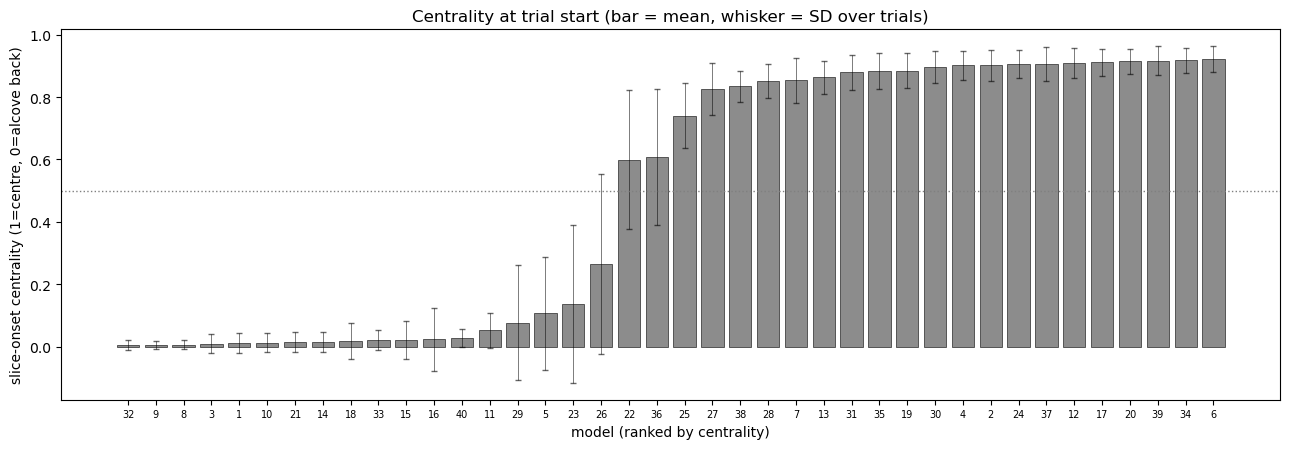

In [5]:
onset_by_model = mc.onset_centrality_by_model(slice_df)

# plot each model's mean onset centrality, ranked
order = onset_by_model.sort_values('onset_centrality').reset_index(drop=True)
x = np.arange(len(order))
fig, ax = plt.subplots(figsize=(13, 4.6))
ax.bar(x, order['onset_centrality'], yerr=order['onset_sd'], capsize=2,
       color='#8C8C8C', edgecolor='black', linewidth=0.4,
       error_kw=dict(lw=0.6, alpha=0.6))
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xticks(x); ax.set_xticklabels(order['model'], fontsize=7)
ax.set_xlabel('model (ranked by centrality)'); ax.set_ylabel('slice-onset centrality (1=centre, 0=alcove back)')
ax.set_title('Centrality at trial start (bar = mean, whisker = SD over trials)')
plt.tight_layout(); plt.show()

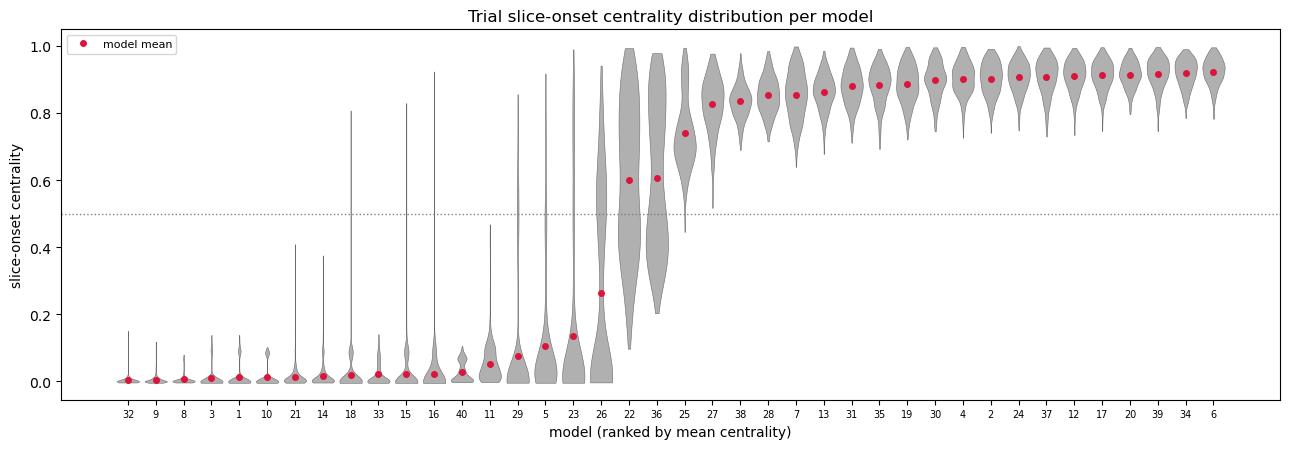

In [6]:
# plot the per-trial spread within each model, ordered by model mean
fig, ax = plt.subplots(figsize=(13, 4.6))
mean_order = onset_by_model.sort_values('onset_centrality')['model'].tolist()
sns.violinplot(data=slice_df, x='model', y='centrality', order=mean_order,
               density_norm='width', inner=None, cut=0, linewidth=0.4,
               color='#B0B0B0', ax=ax)
ax.plot(range(len(mean_order)),
        onset_by_model.set_index('model').loc[mean_order, 'onset_centrality'].values,
        'o', color='crimson', markersize=4, label='model mean')
ax.axhline(0.5, color='grey', ls=':', lw=1)
ax.set_xticks(range(len(mean_order)))
ax.set_xticklabels(mean_order, fontsize=7)
ax.set_xlabel('model (ranked by mean centrality)'); ax.set_ylabel('slice-onset centrality')
ax.set_title('Trial slice-onset centrality distribution per model')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [7]:
# take how far the lowest central model sits from the rest, and how wide the gap between groups is
s = onset_by_model.sort_values('onset_centrality')['onset_centrality'].to_numpy()
gaps = np.diff(s)
i = int(np.argmax(gaps))
print(f"largest gap between neighbouring models: {gaps[i]:.3f} (from {s[i]:.3f} to {s[i + 1]:.3f})")
print(f"models below the gap: {(s <= s[i]).sum()}, above: {(s > s[i]).sum()}")
print(f"spread above the gap: {s[i + 1]:.3f} to {s[-1]:.3f} (SD {s[i + 1:].std(ddof=1):.3f})")
print(f"spread below the gap: {s[0]:.3f} to {s[i]:.3f} (SD {s[:i + 1].std(ddof=1):.3f})")

largest gap between neighbouring models: 0.335 (from 0.265 to 0.599)
models below the gap: 18, above: 22
spread above the gap: 0.599 to 0.922 (SD 0.092)
spread below the gap: 0.004 to 0.265 (SD 0.066)


**Interpretation**

- The models fall into two groups. The largest gap between neighbouring models is 0.335 (from 0.265
  to 0.599), with 18 models below it and 22 above.
- The gap is half the width of 260929's (0.667). Both ends of it are filled by single models: 26
  (0.265) and 23 (0.136) are the least alcove-bound peripheral models, 22 (0.599) and 36 (0.607) the
  least central central models.
- The upper group (0.599-0.922, SD 0.092) is wider than 260929's (SD 0.041). The lower group sits
  near the alcove back (0.004-0.265, SD 0.066).

### Data-driven central vs peripheral split

The models are split two ways. (a) A fixed cut at centrality = 0.5. (b) A 2-component Gaussian
mixture (GMM) fit to the per-model means, which finds its own boundary. If the two agree and the
distribution has a clear gap, the split is real.

`split_strategies` also fits a 3-component mixture and, when it fits better by BIC, tags the
middle component `intermediate`. That label is printed but not used here (see below).

**How to read the figure.** One dot is one model, placed by its mean onset centrality. The vertical
position is random jitter, so the dots do not overlap, and means nothing. The grey curve is a
smoothed density of the model means. The dotted black line is the fixed cut at 0.5. The dashed red
line is the midpoint between the two GMM component means. Dot colour is the GMM label
(blue = central, orange = peripheral).

**Why it is plotted.** It shows whether the models form two separate groups, and whether the
two methods draw the boundary in the same gap.

GMM component means: [0.046 0.856]  weights: [0.55 0.45]
fixed(0.5) vs GMM agreement: 100%
strategy_gmm  strategy_fixed
central       central           22
peripheral    peripheral        18
Name: n, dtype: int64

3-component labels:


strategy
central         [2, 4, 6, 7, 12, 13, 17, 19, 20, 24, 27, 28, 3...
intermediate                                         [22, 25, 36]
peripheral      [1, 3, 5, 8, 9, 10, 11, 14, 15, 16, 18, 21, 23...


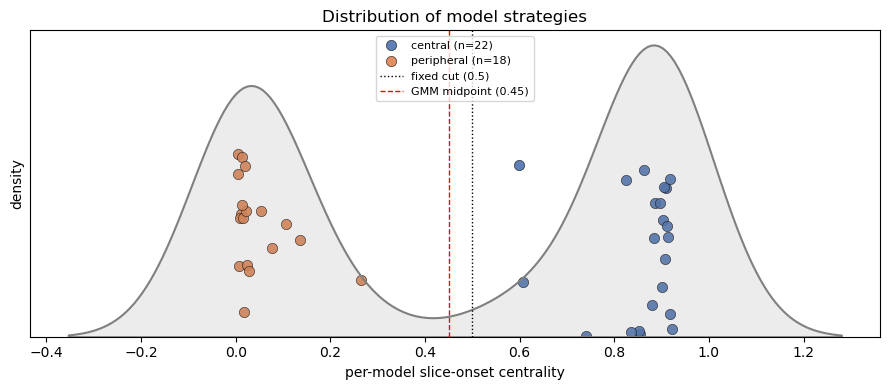

In [8]:
onset_by_model, gmm, boundary = mc.split_strategies(onset_by_model)
mc.report_strategy_split(onset_by_model, gmm)
print()
print("3-component labels:")
print(onset_by_model.groupby('strategy')['model'].apply(list).to_string())

# plot each model on the axis, coloured by the 2-component label
vals = onset_by_model['onset_centrality'].to_numpy()
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(9, 4))
for lab in mc.MAIN_STRATEGIES:
    sub = onset_by_model[onset_by_model['strategy_gmm'] == lab]
    ax.scatter(sub['onset_centrality'], rng.uniform(0, 1, len(sub)), color=mc.STRAT_PALETTE[lab],
               edgecolor='black', linewidth=0.4, s=55, alpha=0.9, label=f'{lab} (n={len(sub)})')
sns.kdeplot(x=vals, ax=ax, color='grey', lw=1.5, fill=True, alpha=0.15, bw_adjust=0.6)
ax.axvline(0.5, color='black', ls=':', lw=1, label='fixed cut (0.5)')
ax.axvline(boundary, color='red', ls='--', lw=1, label=f'GMM midpoint ({boundary:.2f})')
ax.set_yticks([]); ax.set_xlabel('per-model slice-onset centrality'); ax.set_ylabel('density')
ax.set_title('Distribution of model strategies')
ax.legend(fontsize=8, loc='upper center'); plt.tight_layout(); plt.show()

**Interpretation**

- The two methods agree on all 40 models. The GMM component means are 0.046 and 0.856, with
  weights 0.55 and 0.45.
- The 3-component fit tags models 22, 25 and 36 as `intermediate` (0.599-0.741). All three sit on
  the central side of the gap, so the 2-component label is used and they count as central.
- **Assumption to check:** treating 22, 25 and 36 as central rather than as a third group.

In [9]:
# adopt the 2-component label as the working strategy
model_meta = mc.build_model_meta(USABLE_MODELS, onset_by_model, strategy_col='strategy_gmm')
mc.report_strategy_membership(model_meta)

CENTRAL = model_meta.loc[model_meta['strategy'] == 'central', 'model'].astype(int).tolist()
PERIPHERAL = model_meta.loc[model_meta['strategy'] == 'peripheral', 'model'].astype(int).tolist()

Strategy membership (working label = GMM):
  central     (n=22): [2, 4, 6, 7, 12, 13, 17, 19, 20, 22, 24, 25, 27, 28, 30, 31, 34, 35, 36, 37, 38, 39]
  peripheral  (n=18): [1, 3, 5, 8, 9, 10, 11, 14, 15, 16, 18, 21, 23, 26, 29, 32, 33, 40]
  intermediate (n= 0): []
  unassigned  (n= 0): []


## Stage 2 - the fingerprint by strategy

One row per model, with every metric in `mc.FP_METRICS`. In short (full definitions in
`fingerprint_metrics.md`):

| metric | what it measures |
| --- | --- |
| `onset_centrality` | mean centrality at slice onset |
| `iti_centrality` | mean centrality over the ITI frames |
| `prop_no_translational` | share of ITI frames with no translation (step < 0.05 units/frame) |
| `prop_no_rotational` | share of ITI frames with no rotation (< 0.5 deg/frame) |
| `proportion_resting` | share of ITI frames with neither (standing still and not turning) |
| `iti_path_len` | distance travelled per ITI (units) |
| `rot_total` | rotation per ITI (degrees) |
| `winner_path_len` | the winner's route length from slice onset to the trigger |
| `path_ratio` | that route over the straight-line distance (1 = perfectly direct) |
| `frac_visible_at_onset` | share of trials with a trial wall already in view at slice onset |
| `late_latency_to_wall_visible` | time to first see a wall, on trials where none was in view at onset (s) |
| `all_latency_to_wall_visible` | the same over every trial where a wall was seen, counting in-view-at-onset as 0 (s) |
| `latency_to_reach_wall` | median time from slice onset to the trigger (s) |
| `frac_never_visible` | share of trials that ended before a trial wall came into view |
| `frac_trials_over_5s` | share of trials slower than 5 s |
| `p_high` | share of trials won at the High wall |
| `mean_score` | agent 0's mean trial score (1.0 High, 0.4 Low, 0 lost) |
| `score_rate` | total score over total trial time (score per second) |

In [10]:
fingerprint = mc.build_fingerprint(model_meta, tables)
fingerprint[['model', 'strategy'] + mc.FP_METRICS].sort_values(['strategy', 'onset_centrality']).round(3)

,model,strategy,onset_centrality,iti_centrality,prop_no_translational,prop_no_rotational,proportion_resting,iti_path_len,rot_total,winner_path_len,path_ratio,frac_visible_at_onset,late_latency_to_wall_visible,all_latency_to_wall_visible,latency_to_reach_wall,frac_never_visible,frac_trials_over_5s,p_high,mean_score,score_rate
21,22,central,0.599,0.611,0.325,0.057,0.013,28.276,1691.562,23.018,1.259,0.688,0.252,0.079,2.073,0.000,0.011,0.603,0.386,0.256
35,36,central,0.607,0.559,0.145,0.074,0.014,38.256,1658.601,19.206,1.123,0.707,0.408,0.120,1.964,0.000,0.000,0.889,0.466,0.475
24,25,central,0.741,0.674,0.271,0.217,0.056,25.834,1402.891,20.121,1.061,0.717,0.242,0.068,2.077,0.000,0.000,0.919,0.475,0.458
26,27,central,0.825,0.811,0.060,0.176,0.015,46.721,1478.564,20.530,1.137,0.692,0.362,0.112,2.040,0.000,0.000,0.687,0.424,0.394
37,38,central,0.834,0.826,0.041,0.337,0.018,47.424,1183.164,19.180,1.088,0.707,0.647,0.153,1.853,0.073,0.000,0.874,0.448,0.482
27,28,central,0.853,0.869,0.142,0.102,0.011,41.843,1613.455,18.242,1.060,0.710,0.190,0.055,1.820,0.000,0.000,0.889,0.455,0.506
6,7,central,0.854,0.798,0.230,0.186,0.044,34.835,1462.146,19.782,1.054,0.694,0.236,0.072,2.033,0.000,0.000,0.934,0.486,0.473
12,13,central,0.863,0.866,0.104,0.393,0.045,44.382,1084.400,19.112,1.108,0.664,0.881,0.202,1.820,0.139,0.005,0.823,0.389,0.465
30,31,central,0.880,0.864,0.023,0.102,0.006,48.430,1611.528,19.026,1.083,0.717,0.215,0.061,1.890,0.000,0.000,0.899,0.484,0.494
34,35,central,0.884,0.882,0.080,0.142,0.015,43.881,1539.328,19.552,1.094,0.705,0.260,0.077,1.940,0.000,0.000,0.869,0.452,0.468


### How much of each metric is strategy

For each metric, eta² is the share of the spread across models that lies between the two strategy
means (`SS_between / SS_total`). 1 means the metric is fully set by strategy. 0 means the two
groups have the same mean, and all the spread is within them.

This is descriptive. The labels come from onset centrality on the same data, so eta² is circular
for any metric that tracks centrality, and `p_anova` is not a valid test (see the `mc` docstring).
With only a handful of peripheral models, read the group means alongside the eta² ordering.

In [11]:
var_table = mc.between_strategy_variance(fingerprint)
print(f"central n={len(CENTRAL)}, peripheral n={len(PERIPHERAL)}")
var_table.round(3)

central n=22, peripheral n=18


,metric,eta2_between_strategy,p_anova,central_mean,peripheral_mean
0,onset_centrality,0.963,0.000,0.856,0.046
1,iti_centrality,0.961,0.000,0.831,0.051
5,iti_path_len,0.741,0.000,40.522,18.219
2,prop_no_translational,0.723,0.000,0.141,0.538
4,proportion_resting,0.664,0.000,0.024,0.287
13,frac_never_visible,0.659,0.000,0.010,0.146
15,p_high,0.574,0.000,0.862,0.666
3,prop_no_rotational,0.550,0.000,0.155,0.502
6,rot_total,0.550,0.000,1514.777,892.502
8,path_ratio,0.423,0.000,1.090,1.196


**How to read the figure.** One panel per metric. Each dot is one model, split into central (blue)
and peripheral (orange) and jittered sideways so the dots do not overlap. The black bar is the
group mean. The panel title gives the metric's eta² from the table above.

**Why it is plotted.** A mean can hide whether a group difference is every model shifting together
or one or two extreme models. With so few peripheral models, that matters for every metric.

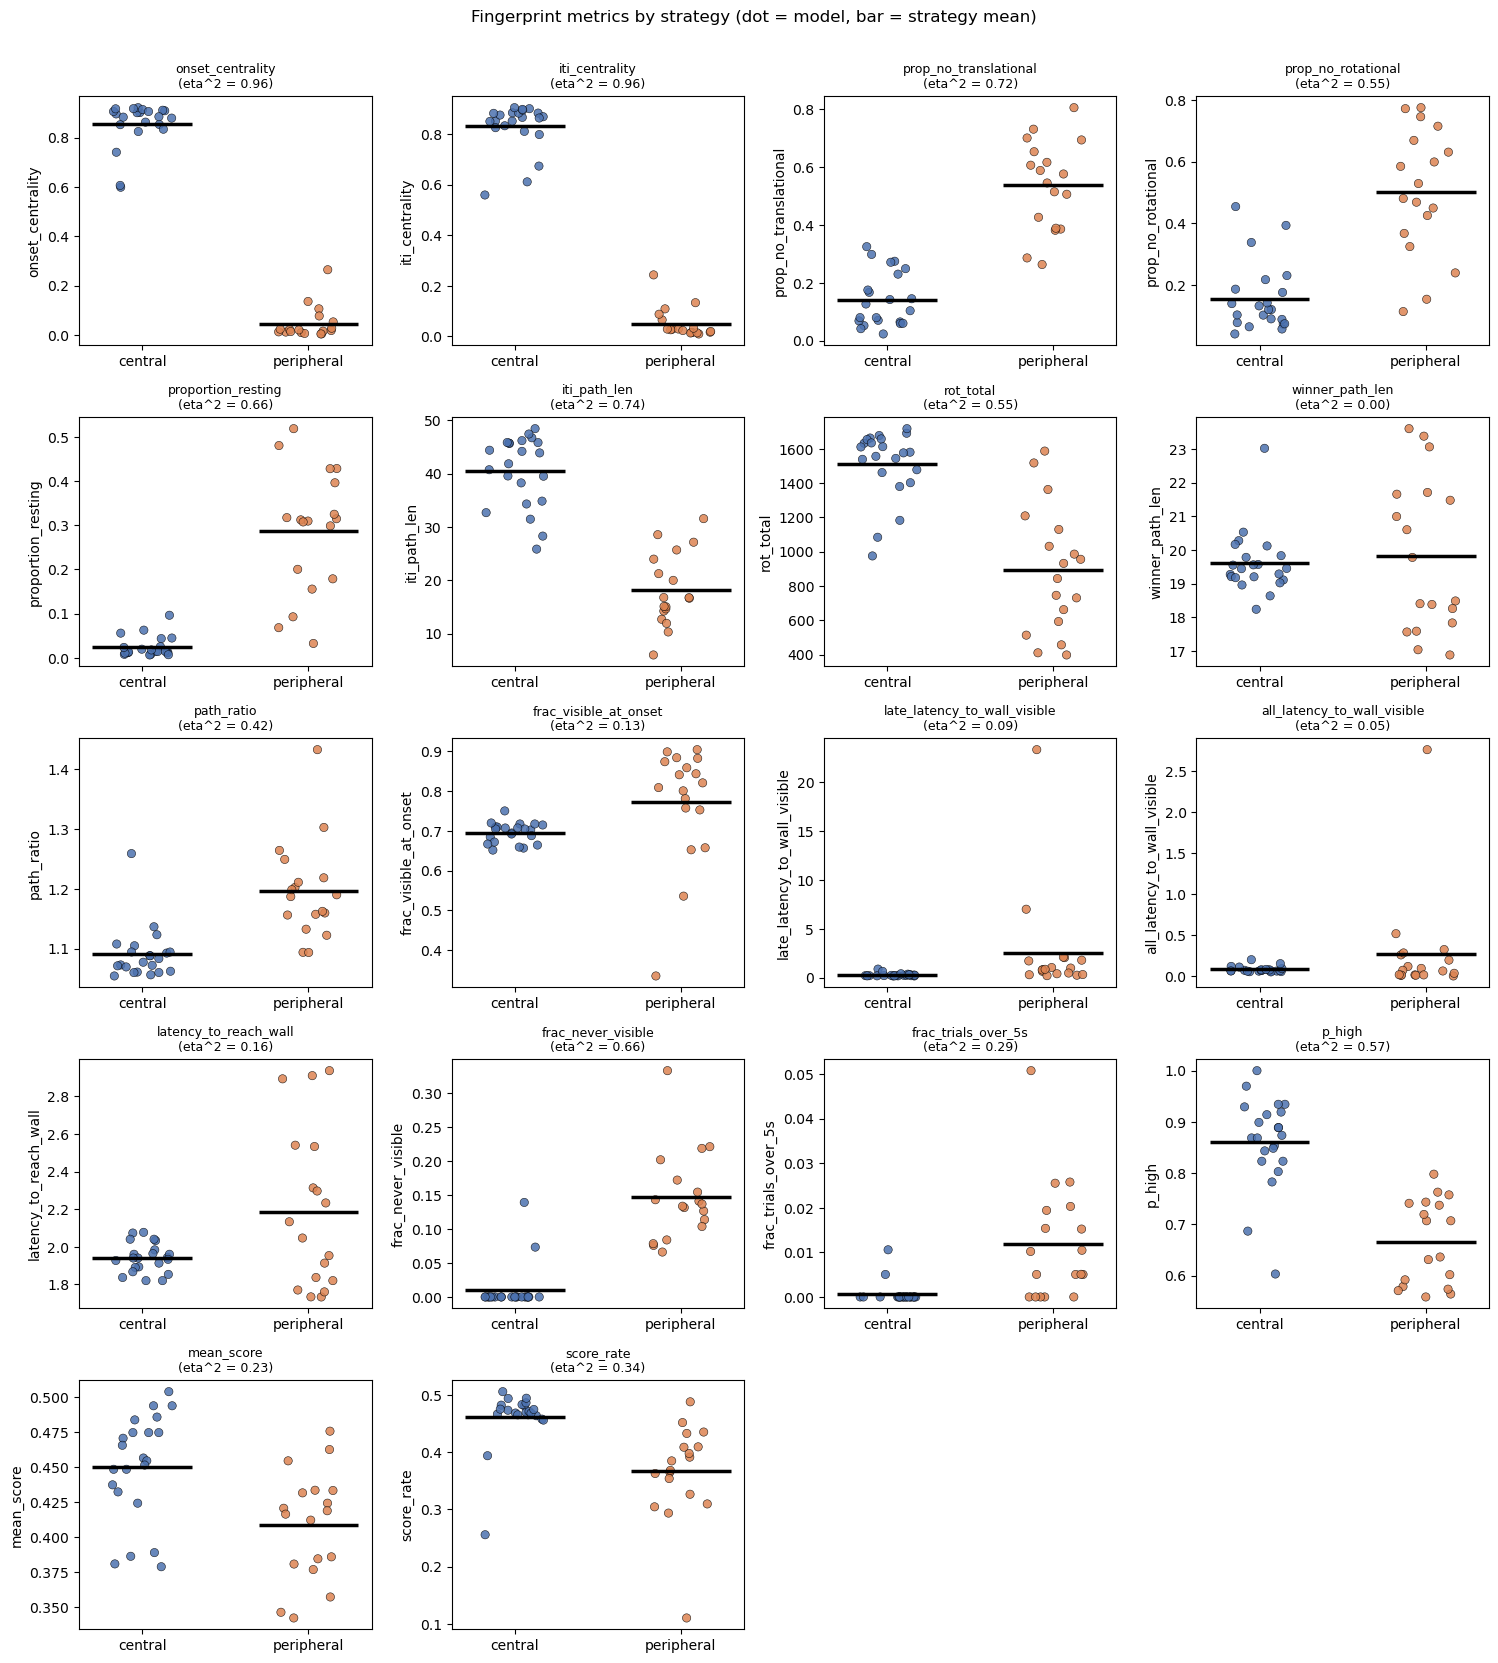

In [12]:
# plot central vs peripheral for each fingerprint metric (dot = model, bar = strategy mean)
ncol = 4
nrow = int(np.ceil(len(mc.FP_METRICS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(15, 3.3 * nrow))
eta = var_table.set_index('metric')['eta2_between_strategy']
for ax, m in zip(axes.ravel(), mc.FP_METRICS):
    sns.stripplot(data=fingerprint, x='strategy', y=m, order=list(mc.MAIN_STRATEGIES),
                  hue='strategy', palette=mc.STRAT_PALETTE, size=6, jitter=0.18,
                  alpha=0.85, edgecolor='black', linewidth=0.4, legend=False, ax=ax)
    means = fingerprint.groupby('strategy')[m].mean()
    for i, g in enumerate(mc.MAIN_STRATEGIES):
        ax.hlines(means[g], i - 0.3, i + 0.3, color='black', lw=2.5, zorder=5)
    ax.set_title(f'{m}\n(eta^2 = {eta[m]:.2f})', fontsize=9); ax.set_xlabel('')
for ax in axes.ravel()[len(mc.FP_METRICS):]:
    ax.axis('off')
plt.suptitle('Fingerprint metrics by strategy (dot = model, bar = strategy mean)', y=1.005)
plt.tight_layout(); plt.show()

### Is the score gap more than the High-wall gap?

In self-play both agents run the same policy, so each wins about half the trials. Terminal score is
1.0 for High, 0.4 for Low and 0 for a loss, so a model's mean score is predicted from `p_high` alone
by `0.5 * (0.4 + 0.6 * p_high)`, with nothing fitted. `residual` is the observed `mean_score` minus
that prediction. A residual near zero means the score follows from the wall choice.

In [13]:
# predict mean score from p_high alone, and compare by strategy
pred = fingerprint[['model', 'strategy', 'p_high', 'mean_score']].copy()
pred['predicted'] = 0.5 * (0.4 + 0.6 * pred['p_high'])
pred['residual'] = pred['mean_score'] - pred['predicted']
pred.groupby('strategy')[['p_high', 'mean_score', 'predicted', 'residual']].agg(['mean', 'min', 'max']).round(3)

p_high               mean_score               predicted               residual              
             mean    min    max       mean    min    max      mean    min    max     mean    min    max
strategy                                                                                               
central     0.862  0.603  1.000      0.450  0.379  0.504     0.459  0.381  0.500   -0.008 -0.080  0.048
peripheral  0.666  0.558  0.798      0.409  0.342  0.476     0.400  0.368  0.439    0.009 -0.026  0.047

**Interpretation**

- The largest eta² values beyond the centrality columns are `iti_path_len` (40.5 against 18.2,
  eta² 0.74), `prop_no_translational` (0.141 against 0.538, 0.72), `proportion_resting` (0.024
  against 0.287, 0.66) and `frac_never_visible` (0.010 against 0.146, 0.66).
- `p_high` separates less than in 260929 (eta² 0.57 against 0.92). Central models choose High on
  0.862 here, against 0.999 there, so the groups are closer (peripheral 0.666).
- Speed to the wall barely separates the groups (1.94 s against 2.19 s, eta² 0.16). Route length
  does not separate them at all (eta² 0.00). Directness does, more than in 260929 (`path_ratio`
  1.090 against 1.196, eta² 0.42).
- Mean score follows the wall choice. The residual from `0.5 * (0.4 + 0.6 * p_high)` averages
  -0.008 for central and +0.009 for peripheral, and every model lies within 0.08 of its prediction.

### Spread within the central group

The spread inside the central group is ranked, as in the 260914 and 260929 notebooks.
`cv` is SD / |mean|, the scale-free measure of spread. It blows up wherever the mean sits near zero,
so read `frac_never_visible` and `frac_trials_over_5s` from their min and max instead. The
peripheral group is too small to rank this way, so its models are listed in full instead.

In [14]:
# summarise how far the central models spread on each metric, ranked by CV
fp_central = fingerprint[fingerprint['strategy'] == 'central']
spread = fp_central[mc.FP_METRICS].agg(['mean', 'median', 'std', 'min', 'max']).T
spread['cv'] = spread['std'] / spread['mean'].abs()
spread = spread.rename_axis('metric').reset_index().sort_values('cv', ascending=False)
print(f"spread across the {len(fp_central)} central models (ranked by CV)")
spread.round(3)

spread across the 22 central models (ranked by CV)


,metric,mean,median,std,min,max,cv
14,frac_trials_over_5s,0.001,0.000,0.002,0.000,0.011,3.452
13,frac_never_visible,0.010,0.000,0.033,0.000,0.139,3.403
4,proportion_resting,0.024,0.014,0.023,0.006,0.096,0.938
3,prop_no_rotational,0.155,0.120,0.111,0.041,0.454,0.715
2,prop_no_translational,0.141,0.115,0.094,0.023,0.325,0.665
10,late_latency_to_wall_visible,0.289,0.227,0.169,0.180,0.881,0.584
11,all_latency_to_wall_visible,0.082,0.069,0.036,0.053,0.202,0.435
5,iti_path_len,40.522,42.862,6.616,25.834,48.430,0.163
6,rot_total,1514.777,1579.000,200.204,975.437,1718.437,0.132
1,iti_centrality,0.831,0.865,0.094,0.559,0.905,0.113


In [15]:
# list the models at either end of the widest-spread metrics. Only metrics whose median sits
# clear of zero are ranked, as CV around a near-zero mean is not comparable
solid = [m for m in spread['metric'] if fp_central[m].median() > 0]
TOP_N = 4
for m in solid[:TOP_N]:
    s = fp_central.set_index('model')[m].sort_values(ascending=False)
    print(f"{m}  (median {s.median():.3f})")
    print(f"   highest: {', '.join(f'{int(i)}={v:.3f}' for i, v in s.head(3).items())}")
    print(f"   lowest : {', '.join(f'{int(i)}={v:.3f}' for i, v in s.tail(3).items())}")
    print()

proportion_resting  (median 0.014)
   highest: 39=0.096, 12=0.063, 25=0.056
   lowest : 19=0.008, 37=0.007, 31=0.006

prop_no_rotational  (median 0.120)
   highest: 39=0.454, 13=0.393, 38=0.337
   lowest : 19=0.064, 22=0.057, 37=0.041

prop_no_translational  (median 0.115)
   highest: 22=0.325, 12=0.298, 6=0.275
   lowest : 17=0.052, 38=0.041, 31=0.023

late_latency_to_wall_visible  (median 0.227)
   highest: 13=0.881, 38=0.647, 36=0.408
   lowest : 37=0.190, 17=0.180, 6=0.180



In [16]:
# show the peripheral models one by one, beside the central median
fp_periph = fingerprint[fingerprint['strategy'] == 'peripheral'].set_index('model')[mc.FP_METRICS].T
fp_periph.columns = [f'model {int(c)}' for c in fp_periph.columns]
fp_periph.insert(0, 'central median', fp_central[mc.FP_METRICS].median())
fp_periph.round(3)

,central median,model 1,model 3,model 5,model 8,model 9,model 10,model 11,model 14,model 15,model 16,model 18,model 21,model 23,model 26,model 29,model 32,model 33,model 40
onset_centrality,0.891,0.012,0.010,0.106,0.006,0.005,0.013,0.053,0.016,0.022,0.023,0.018,0.014,0.136,0.265,0.077,0.004,0.021,0.027
iti_centrality,0.865,0.016,0.016,0.109,0.009,0.016,0.013,0.065,0.019,0.028,0.029,0.026,0.023,0.133,0.243,0.088,0.014,0.029,0.032
prop_no_translational,0.115,0.546,0.654,0.506,0.701,0.589,0.806,0.694,0.386,0.607,0.732,0.577,0.263,0.382,0.286,0.389,0.617,0.427,0.515
prop_no_rotational,0.120,0.324,0.599,0.153,0.715,0.529,0.584,0.449,0.772,0.480,0.425,0.745,0.113,0.775,0.239,0.367,0.669,0.468,0.631
proportion_resting,0.014,0.179,0.396,0.068,0.519,0.315,0.481,0.317,0.299,0.310,0.312,0.429,0.033,0.308,0.093,0.156,0.428,0.200,0.325
iti_path_len,42.862,16.622,12.669,19.971,11.907,16.750,5.977,14.216,25.676,14.629,10.292,15.021,27.128,28.543,31.552,23.953,15.077,21.234,16.721
rot_total,1579.000,1209.309,730.660,1518.195,513.019,843.564,745.496,986.037,410.055,931.980,1031.787,456.447,1587.510,397.364,1363.207,1130.037,592.491,955.828,662.053
winner_path_len,19.451,19.781,23.601,17.569,23.378,16.887,20.604,18.489,23.060,17.042,21.708,21.476,20.994,18.385,17.592,17.837,18.409,21.656,18.264
path_ratio,1.080,1.157,1.433,1.264,1.202,1.094,1.160,1.249,1.162,1.156,1.218,1.303,1.122,1.187,1.211,1.093,1.132,1.190,1.199
frac_visible_at_onset,0.703,0.841,0.757,0.335,0.781,0.859,0.821,0.843,0.874,0.657,0.882,0.809,0.904,0.753,0.536,0.801,0.884,0.898,0.652


**Interpretation**

- Central `p_high` spreads more than in 260929. Median 0.871, range 0.603-1.000. The lowest are
  models 22 (0.603), 27 (0.687) and 19 (0.783).
- Model 22 is the outlier of the group. It is the least central (0.599), has the least direct routes
  (`path_ratio` 1.259) and the lowest score rate (0.256). Part of that score rate comes from its two
  stalled trials (64 s and 118 s).
- Standing still and not turning have the widest spread among metrics clear of zero. Model 39 rests
  most (0.096) and turns least (`prop_no_rotational` 0.454). Models 22, 12 and 6 stand still most
  (0.275-0.325).
- Model 13 takes longest to see a wall when none is in view at onset (0.88 s, median 0.23 s), and
  ends 13.9% of trials without seeing one, the only central model well above zero.
- Among peripheral models, model 3's numbers are dominated by its two stalled trials (score rate
  0.110, `late_latency_to_wall_visible` 23.3 s). Model 5 (centrality 0.106) has a wall in view at
  onset on only 0.335 of trials, and never sees one on 0.332. Resting runs from 0.033 (model 21)
  to 0.519 (model 8).

### Where each strategy stands at slice onset

**How to read the figure.** Each panel is a top-down view of the arena, with the octagon outline in
white. Colour is the number of slice-onset positions in each bin (60 x 60 bins across the arena),
on a log scale (`log(1 + count)`), so bright = many trials start there. Both agents are pooled. The
left panel pools all central models and the right panel all peripheral models.

**Why it is plotted.** Centrality is a distance from the centre and says nothing about direction.
The map shows where around the arena each group waits, for example along walls or in alcoves.

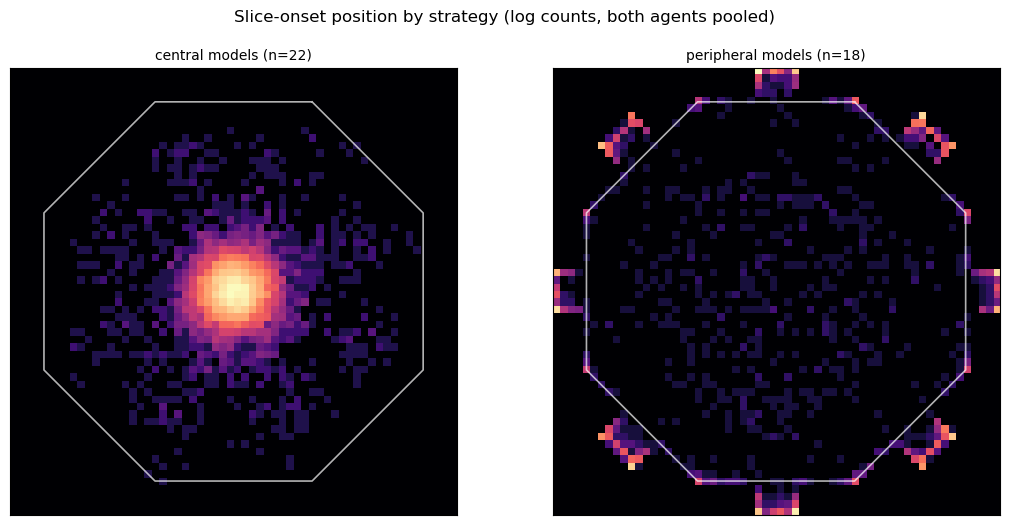

In [17]:
HIST_BINS = 60
R = mc.ARENA_RADIUS
extent = [-R, R, -R, R]
hrange = [[-R, R], [-R, R]]
slice_df['strategy'] = slice_df['model'].map(model_meta.set_index('model')['strategy'])

# plot the slice-onset occupancy of each strategy
oct_x, oct_y = plot_octagon.calculate_coordinates(vertex=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
for ax, lab in zip(axes, mc.MAIN_STRATEGIES):
    sub = slice_df[slice_df['strategy'] == lab]
    H, _, _ = np.histogram2d(sub['x'].to_numpy(float), sub['z'].to_numpy(float),
                             bins=HIST_BINS, range=hrange)
    ax.imshow(np.log1p(H).T, origin='lower', extent=extent, cmap='magma', aspect='equal')
    ax.plot(oct_x, oct_y, color='white', lw=1.2, alpha=0.7)
    ax.set_title(f'{lab} models (n={(model_meta.strategy == lab).sum()})', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle('Slice-onset position by strategy (log counts, both agents pooled)', y=1.0)
plt.tight_layout(); plt.show()

### When each strategy first sees a wall

**How to read the figure.** Top panel: the y-axis is the share of trials in which either trial wall
has entered the agent's FoV by the time on the x-axis (seconds from slice onset). Thin lines are
single models, bold lines the strategy mean (blue = central, orange = peripheral). The value at
t = 0 is `frac_visible_at_onset`. A trial that ends before a wall comes into view never counts as
seen, so each curve plateaus at `1 - frac_never_visible` rather than reaching 1.

Bottom panel: the share of trials still running at each time, per strategy mean. It shows how many
trials are left to contribute to the top curve.

**Why it is plotted.** Waiting position sets how often a wall is already in view when the trial
starts, and how long the agent has to turn before it sees one.

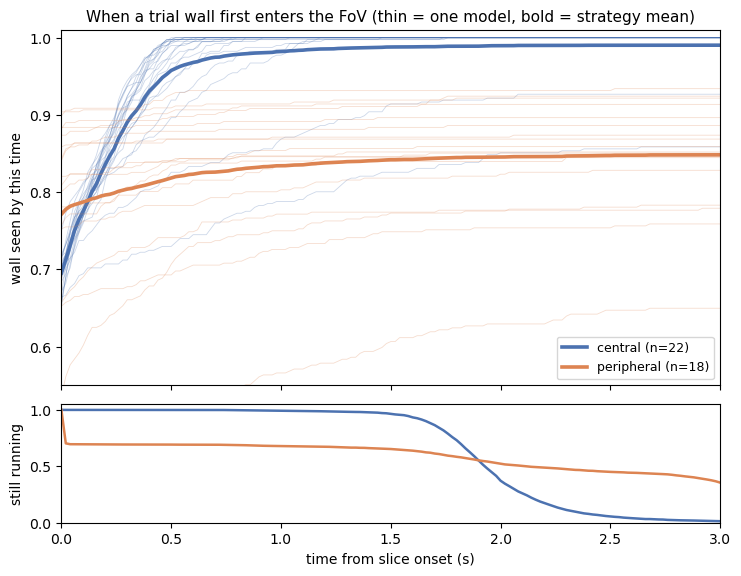

central curve overtakes peripheral at 0.14 s


,at_onset,at_3s
strategy,,
central,0.695,0.990
peripheral,0.771,0.848


In [18]:
# take the cumulative visibility curve for every model
curve = mc.wall_visible_curve(tables['vis'], model_meta, max_s=3.0)

fig, (ax, axr) = plt.subplots(2, 1, figsize=(8.5, 6.4), sharex=True,
                              gridspec_kw=dict(height_ratios=[3, 1], hspace=0.08))
for lab in mc.MAIN_STRATEGIES:
    sub = curve[curve['strategy'] == lab]
    # plot one thin line per model, so within-strategy spread stays visible
    for _, g in sub.groupby('model'):
        ax.plot(g['t'], g['p_visible'], color=mc.STRAT_PALETTE[lab], lw=0.6, alpha=0.28)
    # plot the strategy mean over the top
    m = sub.groupby('t')[['p_visible', 'p_running']].mean()
    ax.plot(m.index, m['p_visible'], color=mc.STRAT_PALETTE[lab], lw=2.6,
            label=f"{lab} (n={sub['model'].nunique()})")
    # plot how many trials are still going
    axr.plot(m.index, m['p_running'], color=mc.STRAT_PALETTE[lab], lw=1.8)

ax.set_ylim(0.55, 1.01); ax.set_ylabel('wall seen by this time')
ax.set_title('When a trial wall first enters the FoV (thin = one model, bold = strategy mean)',
             fontsize=11)
ax.legend(fontsize=9, loc='lower right')
axr.set_ylim(0, 1.05); axr.set_xlim(0, 3)
axr.set_ylabel('still running'); axr.set_xlabel('time from slice onset (s)')
plt.show()

# find the first time the central mean curve overtakes the peripheral one
means = curve.groupby(['strategy', 't'])['p_visible'].mean().unstack(0)
ahead = (means['central'] > means['peripheral']).to_numpy()
print(f"central curve overtakes peripheral at {means.index[np.argmax(ahead)]:.2f} s" if ahead.any()
      else "central curve never overtakes peripheral")

# print the values the curves start and end at
ends = curve.groupby(['strategy', 'model']).agg(at_onset=('p_visible', 'first'),
                                                 at_3s=('p_visible', 'last')).groupby('strategy').mean()
ends.round(3)

**Interpretation**

- Peripheral models start with a wall in view more often (0.771 against 0.695 at t = 0).
- The central mean curve overtakes the peripheral one at 0.14 s.
- By 3 s, 0.990 of central trials have had a wall in view, against 0.848 for peripheral.

## Stage 3 - multivariate fingerprint

PCA of the standardised fingerprint, with the two centrality columns left out (`mc.PCA_METRICS`).
If PC1 still tracks centrality, the strategies differ in their movement, visibility and scoring
too, not only in where they stand.

**How to read the figure.** One dot is one model, placed by its scores on the first two principal
components. Each axis label gives the share of the total spread that component explains. Colour is
the strategy label, and numbers are model IDs. The loadings table below gives how strongly each
metric contributes to each component, and in which direction.

**Why it is plotted.** It tests whether the strategy split is one axis among several, or the main
thing that tells these models apart.

PC1 explains 51%, PC2 17% of fingerprint variance
corr(PC1, slice-onset centrality) = -0.87  (|r|~1 => centrality is the main axis; ~0 => something else is)


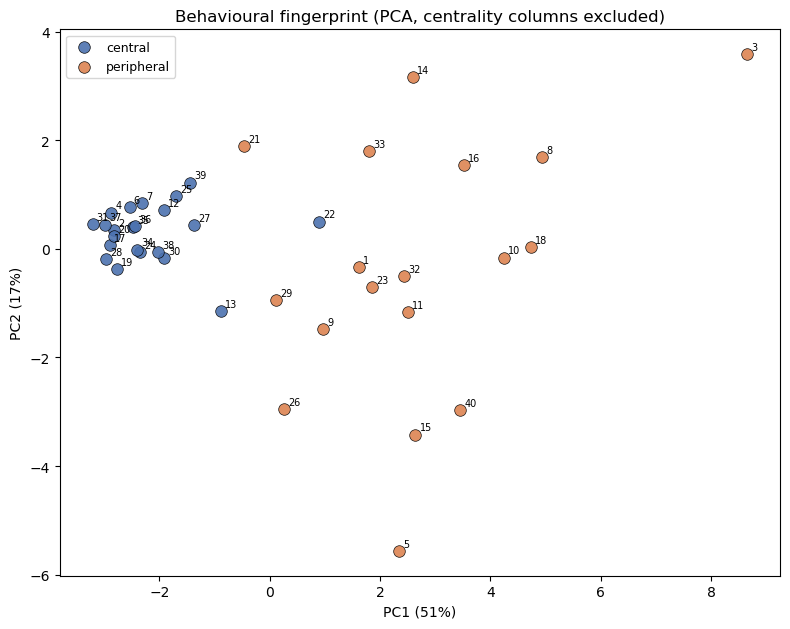

In [19]:
fingerprint, pca = mc.add_fingerprint_pca(fingerprint)
mc.report_pca(fingerprint, pca)

# plot every model on the first two components
fig, ax = plt.subplots(figsize=(8, 6.4))
for lab in mc.MAIN_STRATEGIES:
    sub = fingerprint[fingerprint['strategy'] == lab]
    ax.scatter(sub['pc1'], sub['pc2'], s=70, color=mc.STRAT_PALETTE[lab],
               edgecolor='black', linewidth=0.5, label=lab, alpha=0.9)
for _, r in fingerprint.iterrows():
    ax.annotate(int(r['model']), (r['pc1'], r['pc2']), fontsize=7, xytext=(3, 3),
                textcoords='offset points')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
ax.set_title('Behavioural fingerprint (PCA, centrality columns excluded)')
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

In [20]:
# show which metrics load on each component, so the axes can be read
loadings = pd.DataFrame(pca.components_.T, index=mc.PCA_METRICS, columns=['pc1', 'pc2'])
loadings.reindex(loadings['pc1'].abs().sort_values(ascending=False).index).round(2)

,pc1,pc2
proportion_resting,0.31,0.01
prop_no_translational,0.31,-0.06
iti_path_len,-0.31,0.05
score_rate,-0.31,-0.13
path_ratio,0.30,-0.01
prop_no_rotational,0.28,0.03
rot_total,-0.28,-0.03
p_high,-0.28,0.24
frac_never_visible,0.25,-0.37
late_latency_to_wall_visible,0.21,0.21


In [21]:
# repeat the PCA on the central models only, to see what organises the group without the split
fp_c, pca_c = mc.add_fingerprint_pca(fingerprint[fingerprint['strategy'] == 'central'].drop(columns=['pc1', 'pc2']))
mc.report_pca(fp_c, pca_c)
pd.DataFrame(pca_c.components_.T, index=mc.PCA_METRICS, columns=['pc1', 'pc2']) \
    .sort_values('pc1', key=abs, ascending=False).round(2)

PC1 explains 31%, PC2 28% of fingerprint variance
corr(PC1, slice-onset centrality) = +0.66  (|r|~1 => centrality is the main axis; ~0 => something else is)


,pc1,pc2
score_rate,0.43,0.06
winner_path_len,-0.42,-0.08
frac_trials_over_5s,-0.39,0.08
path_ratio,-0.39,-0.03
p_high,0.30,0.02
latency_to_reach_wall,-0.28,-0.13
prop_no_translational,-0.26,-0.03
iti_path_len,0.26,0.03
mean_score,0.17,-0.07
proportion_resting,-0.07,0.23


In [22]:
# check whether the central-only link to centrality rests on the two lowest central models
low = fp_c.nsmallest(2, 'onset_centrality')['model'].astype(int).tolist()
for drop in ([], low[:1], low):
    f, p = mc.add_fingerprint_pca(fp_c[~fp_c['model'].isin(drop)].drop(columns=['pc1', 'pc2']))
    r = np.corrcoef(f['pc1'], f['onset_centrality'])[0, 1]
    print(f"dropped {str(drop):9s} PC1 {p.explained_variance_ratio_[0]:.0%}  corr(PC1, centrality) = {r:+.2f}")

dropped []        PC1 31%  corr(PC1, centrality) = +0.66
dropped [22]      PC1 32%  corr(PC1, centrality) = -0.13
dropped [22, 36]  PC1 33%  corr(PC1, centrality) = -0.21


**Interpretation**

- Across the whole batch, PC1 explains 51% and correlates -0.87 with onset centrality (the sign is
  arbitrary), with the centrality columns left out. The strategies differ on most metrics at once.
- PC1 loads evenly (|0.28-0.31|) on ITI movement and resting, score rate, `p_high` and route
  directness. PC2 (17%) loads on route length (0.48), time to the wall (0.44) and visibility.
- Within the central group alone, PC1 explains 31% and loads on score rate (0.43) against route
  length, directness and slow trials. Its correlation with centrality (+0.66) rests on model 22
  alone. It falls to -0.13 without 22.
- So within the central group there is no single main axis (PC1 31%, PC2 28%), and model 22 is the
  one model that is both less central and worse on the race.

## Stage 4 - seeds and the earlier batches

261020 differs from 260929 in the build, gamma and `max_steps`, and from 260723 in the build and the
schedules (header table). Three questions.

1. **Does a seed keep its strategy across batches?** Model `NNNN` here trains on the same seed as
   `260929_NNNN` and `260914_NNNN`, from the standard seed list. 260723 used seed 17 for every run, so
   it cannot be paired and enters as a group only.
2. **How often does a seed end up peripheral in each batch?**
3. **How do the central and peripheral groups compare across the batches?**

All batches are labelled by one rule here, so the counts compare like for like: a model is
**peripheral when its mean onset centrality is below 0.5**. Each batch's own GMM split is printed
alongside it. All are finished policies (260723 and 261020 at 4e6, 260914 and 260929 at 7e6).

260929 enters with all 40 of its simulated models, so its tables are cached under their own name
and the 260929 notebook's 33-model cache is left alone.

In [23]:
import analysis.human_agent_comparison as hac
from scipy import stats

CUT = 0.5                           # peripheral below this mean onset centrality, in every batch

# load the long tables of the earlier batches
SIM_260929 = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', '260929')
SIM_260914 = os.path.join(data_strings.SIM_DATA_FOLDER, '2609', '260914')
SIM_260723 = os.path.join(data_strings.SIM_DATA_FOLDER, '2607', '260723')
models_929 = mc.get_batch_models(SIM_260929)
models_914, models_723 = mc.get_batch_models(SIM_260914), mc.get_batch_models(SIM_260723)
tables_929 = data_saving.cached('model_characterisation_260929_all',
                                lambda: mc.collect_model_data(SIM_260929, models=models_929,
                                                              fov=CURRENT_FOV, verbose=False),
                                recompute=RECOMPUTE, stamp=tuple(models_929))
tables_914 = hac.load_agent_tables(SIM_260914, models_914, fov=CURRENT_FOV, recompute=RECOMPUTE)
tables_723 = data_saving.cached('model_characterisation_260723',
                                lambda: mc.collect_model_data(SIM_260723, models=models_723,
                                                              fov=CURRENT_FOV, verbose=False),
                                recompute=RECOMPUTE, stamp=tuple(models_723))


def batch_fingerprint(tables, batch):
    ''' Return one batch's fingerprint, labelled by the common cut and by its own GMM.
        Takes the batch's long tables and its name. '''

    onset, _, _ = mc.split_strategies(mc.onset_centrality_by_model(tables['slice']))
    meta = mc.build_model_meta(sorted(onset['model']), onset, strategy_col='strategy_gmm')
    fp = mc.build_fingerprint(meta, tables)
    fp['strategy'] = np.where(fp['onset_centrality'] < CUT, 'peripheral', 'central')
    return fp.assign(batch=batch)


fp_batches = {'260723': batch_fingerprint(tables_723, '260723'),
              '260914': batch_fingerprint(tables_914, '260914'),
              '260929': batch_fingerprint(tables_929, '260929'),
              BATCH: batch_fingerprint(tables, BATCH)}
for b, f in fp_batches.items():
    print(f"{b}: {len(f)} models, peripheral by cut {(f.strategy == 'peripheral').sum()}, "
          f"by own GMM {(f.strategy_gmm == 'peripheral').sum()}")

model_characterisation_260929_all: loaded from cache
agent_tables: loaded from cache
model_characterisation_260723: loaded from cache


260723: 55 models, peripheral by cut 26, by own GMM 24
260914: 30 models, peripheral by cut 2, by own GMM 3
260929: 40 models, peripheral by cut 7, by own GMM 6
261020: 40 models, peripheral by cut 18, by own GMM 18


### Does a seed keep its strategy?

**How to read the figure.** One dot is one seed, labelled with its model number. The x-axis is that
seed's mean onset centrality in the earlier batch (260929 left, 260914 right), the y-axis in 261020.
Dotted lines mark the 0.5 cut on each axis. A seed that kept its strategy sits in the top-right box
(central in both) or the bottom-left box (peripheral in both). Orange dots changed strategy.

**Why it is plotted.** If the seed decided the strategy, peripheral seeds would stay peripheral and
the dots would lie along the diagonal.

seeds trained in both 260929 and 261020: 39
261020      central  peripheral
260929                         
central          19          13
peripheral        2           5
rank correlation of onset centrality across the pairs: +0.28 (p = 0.08)

seeds trained in both 260914 and 261020: 30
261020      central  peripheral
260914                         
central          14          14
peripheral        1           1
rank correlation of onset centrality across the pairs: +0.17 (p = 0.37)



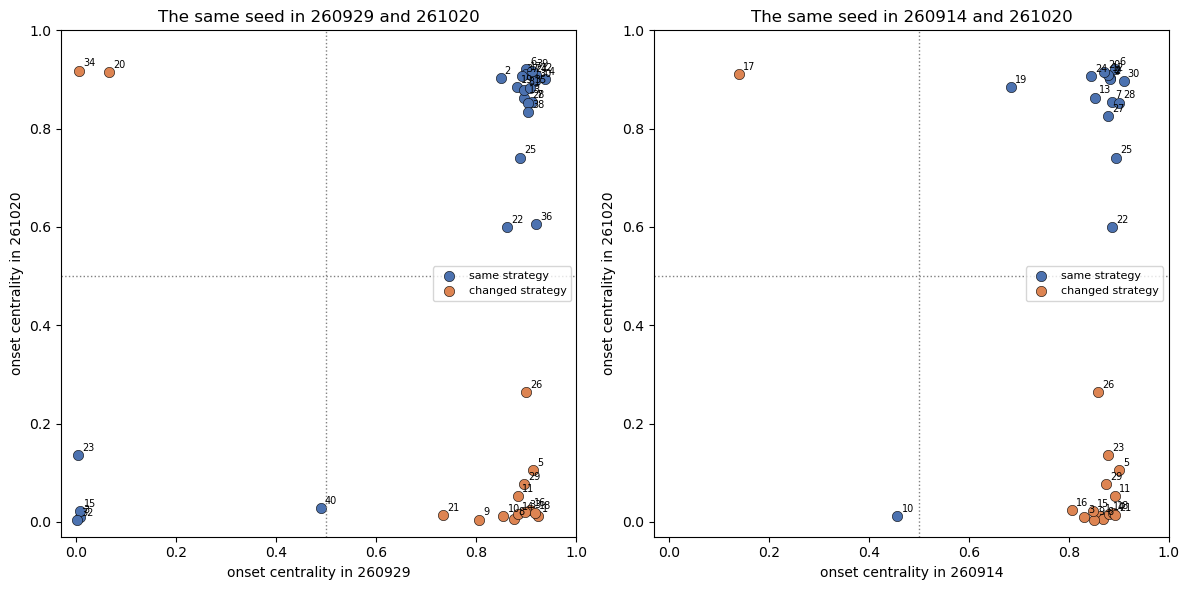

,onset_261020,onset_260929,onset_260914
model,,,
1,0.012,0.922,0.863
3,0.010,0.006,0.831
5,0.106,0.913,0.900
8,0.006,0.875,0.868
9,0.005,0.805,0.851
10,0.013,0.854,0.457
11,0.053,0.883,0.892
14,0.016,0.882,0.880
15,0.022,0.006,0.847


In [24]:
# pair each seed's centrality with 260929 and 260914
def pair_with(other):
    ''' Return one row per seed trained in both batches. Takes the earlier batch's name. '''

    cols = ['onset_centrality', 'strategy', 'p_high']
    p = (fp_batches[other].set_index('model')[cols]
         .join(fp_batches[BATCH].set_index('model')[cols], lsuffix='_other', rsuffix='_this', how='inner'))
    p['changed'] = p['strategy_other'] != p['strategy_this']
    return p


paired = {o: pair_with(o) for o in ('260929', '260914')}
for o, p in paired.items():
    print(f"seeds trained in both {o} and {BATCH}: {len(p)}")
    print(pd.crosstab(p['strategy_other'], p['strategy_this'], rownames=[o], colnames=[BATCH]))
    rho, pv = stats.spearmanr(p['onset_centrality_other'], p['onset_centrality_this'])
    print(f"rank correlation of onset centrality across the pairs: {rho:+.2f} (p = {pv:.2f})\n")

# plot each seed's centrality in the two batches
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, (o, p) in zip(axes, paired.items()):
    for chg, col in ((False, '#4C72B0'), (True, '#DD8452')):
        sub = p[p['changed'] == chg]
        ax.scatter(sub['onset_centrality_other'], sub['onset_centrality_this'], s=55, color=col,
                   edgecolor='black', linewidth=0.4, label='changed strategy' if chg else 'same strategy')
    for m, r in p.iterrows():
        ax.annotate(int(m), (r['onset_centrality_other'], r['onset_centrality_this']), fontsize=7,
                    xytext=(3, 3), textcoords='offset points')
    ax.axvline(CUT, color='grey', ls=':', lw=1); ax.axhline(CUT, color='grey', ls=':', lw=1)
    ax.set_xlim(-0.03, 1); ax.set_ylim(-0.03, 1)
    ax.set_xlabel(f'onset centrality in {o}'); ax.set_ylabel(f'onset centrality in {BATCH}')
    ax.set_title(f'The same seed in {o} and {BATCH}')
    ax.legend(fontsize=8, loc='center right')
plt.tight_layout(); plt.show()

# list the seeds that are peripheral in 261020, with their strategy in the earlier batches
periph_this = paired['260929'].index[paired['260929']['strategy_this'] == 'peripheral']
pd.DataFrame({'onset_' + BATCH: paired['260929'].loc[periph_this, 'onset_centrality_this'],
              'onset_260929': paired['260929'].loc[periph_this, 'onset_centrality_other'],
              'onset_260914': paired['260914']['onset_centrality_other'].reindex(periph_this)}).round(3)

**Interpretation**

- 39 seeds pair with 260929 and 30 with 260914.
- Against 260929, 5 of the 7 seeds peripheral there are peripheral here (3, 15, 23, 32 and 40). Model
  40 was borderline there (0.489). 13 of its 32 central seeds turned peripheral here.
- Against 260914, its two peripheral seeds split one each way (10 peripheral here, 17 central).
- Onset centrality carries over weakly (rank correlation +0.28, p = 0.08 with 260929; +0.17,
  p = 0.37 with 260914).
- A seed peripheral in 260929 is somewhat more likely to be peripheral here (5 of 7, against 13 of
  32). With 7 seeds this is not a firm result. Most of the change in share comes from central seeds
  turning peripheral, as expected when the share goes up.

### How often a seed ends up peripheral

`share` is the fraction of each batch's models below the cut. `ci_low` and `ci_high` are the exact
(Clopper-Pearson) 95% interval on that fraction, so they show how far the share could move with
a different draw of seeds. The second table gives Fisher's exact test on each pair of batches.

In [25]:
# count the peripheral models in each batch, with an exact interval on the share
rows = []
for b, f in fp_batches.items():
    k, n = int((f['strategy'] == 'peripheral').sum()), len(f)
    ci = stats.binomtest(k, n).proportion_ci(method='exact')
    rows.append(dict(batch=b, peripheral=k, models=n, share=k / n, ci_low=ci.low, ci_high=ci.high))
share = pd.DataFrame(rows).set_index('batch')
display(share.round(3))

# test the peripheral share of this batch against each earlier batch
tests = []
for b in ('260723', '260914', '260929'):
    ka, na, kb, nb_ = share.loc[BATCH, 'peripheral'], share.loc[BATCH, 'models'], share.loc[b, 'peripheral'], share.loc[b, 'models']
    tests.append(dict(pair=f'{BATCH} vs {b}', p_fisher=stats.fisher_exact([[ka, na - ka], [kb, nb_ - kb]])[1]))
pd.DataFrame(tests).round(4)

,peripheral,models,share,ci_low,ci_high
batch,,,,,
260723,26,55,0.473,0.337,0.612
260914,2,30,0.067,0.008,0.221
260929,7,40,0.175,0.073,0.328
261020,18,40,0.450,0.293,0.615


,pair,p_fisher
0,261020 vs 260723,0.8383
1,261020 vs 260914,0.0004
2,261020 vs 260929,0.0150


**Interpretation**

- 18 of 40 261020 models are peripheral (0.450, interval 0.293-0.615). That matches 260723 (0.473,
  p = 0.84) and is clearly above 260929 (0.175, p = 0.015) and 260914 (0.067, p = 0.0004).
- Each batch's own GMM gives the same picture (24, 3, 6 and 18 peripheral models).
- 261020 differs from 260929 in gamma, `max_steps` and the build. Putting gamma back to 0.99 puts the
  peripheral share back to the 260723 level, as intended. The build and `max_steps` changes cannot
  be separated from gamma here.

### The groups across the batches

Group means of the main fingerprint metrics, for each strategy in each batch. `n` is the number of
models in the group. 260723 and 261020 are at 4e6 steps, 260914 and 260929 at 7e6. A group of one
or two models should be read as single points.

In [26]:
# compare group means across the batches
CMP = ['onset_centrality', 'p_high', 'proportion_resting', 'prop_no_translational', 'iti_path_len',
       'rot_total', 'frac_visible_at_onset', 'frac_never_visible', 'latency_to_reach_wall',
       'path_ratio', 'mean_score', 'score_rate']
all_fp = pd.concat(fp_batches.values(), ignore_index=True)
groups = all_fp.groupby(['strategy', 'batch'])[CMP].mean().T
groups.loc['n'] = all_fp.groupby(['strategy', 'batch']).size()
groups.round(3)

strategy                central                               peripheral                            
batch                    260723    260914    260929    261020     260723    260914   260929   261020
onset_centrality          0.835     0.867     0.891     0.856      0.088     0.298    0.082    0.046
p_high                    0.851     0.966     0.999     0.862      0.628     0.854    0.807    0.666
proportion_resting        0.027     0.051     0.017     0.024      0.102     0.009    0.335    0.287
prop_no_translational     0.126     0.182     0.108     0.141      0.242     0.099    0.552    0.538
iti_path_len             43.323    40.345    43.898    40.522     33.546    43.960   18.563   18.219
rot_total              1440.730  1379.113  1484.580  1514.777   1076.272  1487.746  749.216  892.502
frac_visible_at_onset     0.685     0.682     0.693     0.695      0.764     0.696    0.804    0.771
frac_never_visible        0.000     0.003     0.009     0.010      0.108     0.038    0.117    0.146
latency_to_reach_wall     2.068     2.076     2.006     1.941      2.297     2.305    2.662    2.186
path_ratio                1.164     1.165     1.155     1.090      1.334     1.332    1.216    1.196
mean_score                0.458     0.499     0.519     0.450      0.389     0.439    0.400    0.409
score_rate                0.437     0.463     0.475     0.461      0.348     0.386    0.383    0.366
n                        29.000    28.000    33.000    22.000     26.000     2.000    7.000   18.000

**Interpretation**

- Central models look like 260723's in wall choice (`p_high` 0.862 against 0.851; 0.999 in 260929)
  and mean score (0.450 against 0.458). They are faster to the wall than in any earlier batch
  (1.941 s) and take more direct routes (`path_ratio` 1.090 against 1.155-1.165).
- Peripheral models are similar to 260929's, not 260723's, in how they wait. Resting 0.287 (260929
  0.335, 260723 0.102), standing still 0.538 (0.552, 0.242) and ITI path 18.2 units (18.6, 33.5).
  They sit deeper in the alcove than either (centrality 0.046).
- They choose High about as rarely as 260723's (0.666 against 0.628; 260929 0.807), and are faster
  to the wall than 260929's (2.186 s against 2.662 s).
- So gamma tracks the share of peripheral models and the High preference, which both return to
  the 260723 level. The heavy resting of peripheral models stays at the 260929 level. 261020 and
  260929 share the constant learning rate and epsilon schedules, which 260723 does not, so the
  schedules (or the build) are the candidates for the resting difference. This is not tested here.

### Conclusion

- **Gamma 0.99 gives a mixed batch again.** 18 peripheral and 22 central models, the 260723 share.
- **The opponent-sensing build has not changed the broad behaviour.** The fingerprint by strategy
  looks like 260723 and 260929. Whether the networks use the opponent input needs the checks in
  `notes.txt` (`policy_replay.opponent_input_check` and a cross-model tournament).
- **Stalled trials need a look.** Model 3 has two long trials with both agents standing still a
  metre apart. Whether that relates to the opponent-proximity input, which is high when the agents
  are that close, is not tested here. The rate is similar to 260723's.
- **Caveats.** 261020 differs from 260929 in three things (gamma, `max_steps`, build) and from 260723
  in two (schedules, build). The 261020 training curves have not been checked for convergence.